In [5]:
import numpy as np
from numpy import arange
from numpy import mean
from numpy import std
import pandas as pd
import sklearn
import seaborn as sns
import re
import xgboost
import sklearn
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

covariates = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model1_covariates.csv")
# rename sample id column
covariates.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
covariates.set_index('sample_id', inplace=True)

microbes = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model2_asvs_covariates.csv")
# rename sample id column
microbes.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
microbes.set_index('sample_id', inplace=True)

kegg = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model3_kegg_covariates.csv")
kegg.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
kegg.set_index('sample_id', inplace=True)

ec = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model4_ec_covariates.csv")
ec.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
ec.set_index('sample_id', inplace=True)

pathway = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model5_pathways_covariates.csv")
pathway.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
pathway.set_index('sample_id', inplace=True)

microbes_keggs = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model6_asvs_kegg_combined.csv")
microbes_keggs.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
microbes_keggs.set_index('sample_id', inplace=True)

microbes_ecs = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model7_asvs_ec_combined.csv")
microbes_ecs.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
microbes_ecs.set_index('sample_id', inplace=True)

microbes_pws = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model8_asvs_pathways_combined.csv")
microbes_pws.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
microbes_pws.set_index('sample_id', inplace=True)

asvs_kegg_pw = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model9_asvs_kegg_pathways_combined.csv")
asvs_kegg_pw.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
asvs_kegg_pw.set_index('sample_id', inplace=True)

asvs_ec_pw = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model10_asvs_ecs_pathways_combined.csv")
asvs_ec_pw.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
asvs_ec_pw.set_index('sample_id', inplace=True)

datasets = [covariates, microbes, kegg, ec, pathway, microbes_keggs, microbes_ecs, microbes_pws, asvs_kegg_pw, asvs_ec_pw]
dataset_names = ['null', 'asvs', 'kegg', 'enzymes', 'pathways', 'asvs & keggs', 'asvs & ecs', 'asvs & pws', 'asvs, keggs, pathways', 'asvs, ecs, pathways']

# Set the default font to Arial
plt.rcParams['font.family'] = 'Arial'

for dataset, name in zip(datasets, dataset_names):
    print(name)
    print("N samples:", dataset.shape[0])
    print("Missing sex:", dataset["sex"].isna().sum())

    print(dataset["sex"].value_counts(dropna=False))
    print()

datasets_1 = [covariates, microbes, kegg, ec, pathway]
datasets_2 = [microbes_keggs, microbes_ecs, microbes_pws, asvs_kegg_pw, asvs_ec_pw]
dataset_1_names = ['null', 'asvs', 'kegg', 'enzymes', 'pathways']
dataset_2_names = ['asvs & keggs', 'asvs & ecs', 'asvs & pws', 'asvs, keggs, pathways', 'asvs, ecs, pathways']
colors_1 = ['#30362F', '#90323D', '#B185A7', '#36827F', '#160C28']
colors_2 = ['#5A0812', '#B13594', '#094E4B', '#6C4CA7', '#25601B']

null
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

kegg
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

enzymes
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

pathways
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs & keggs
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs & ecs
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs & pws
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs, keggs, pathways
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs, ecs, pathways
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

# ============================================================
# DATASET GROUPS
# ============================================================

datasets_1 = [
    covariates,
    microbes,
    kegg,
    ec,
    pathway
]

dataset_1_names = [
    "null",
    "asvs",
    "kegg",
    "enzymes",
    "pathways"
]

colors_1 = [
    "#30362F",
    "#90323D",
    "#B185A7",
    "#36827F",
    "#160C28"
]


datasets_2 = [
    microbes_keggs,
    microbes_ecs,
    microbes_pws,
    asvs_kegg_pw,
    asvs_ec_pw
]

dataset_2_names = [
    "asvs & keggs",
    "asvs & ecs",
    "asvs & pws",
    "asvs, keggs, pathways",
    "asvs, ecs, pathways"
]

colors_2 = [
    "#5A0812",
    "#B13594",
    "#094E4B",
    "#6C4CA7",
    "#25601B"
]


# ============================================================
# GLOBAL FONT
# ============================================================

plt.rcParams["font.family"] = "Arial"


# ============================================================
# FUNCTION TO RUN NESTED CV + PLOT ROC
# ============================================================

def run_nested_cv_group(
    datasets,
    dataset_names,
    colors,
    output_png,
    group_name
):
    """
    Run nested CV for a group of datasets, plot mean ROC curves,
    save figure, and return fold-level AUCs, AUC summary,
    and best hyperparameters.
    """

    fig, ax = plt.subplots(
        figsize=(10, 8)
    )

    legend_handles = []

    group_fold_results = []
    group_best_params = []

    for dataset, name, color in zip(
        datasets,
        dataset_names,
        colors
    ):

        print(
            "\n============================================"
        )
        print(
            f"Dataset: {name}"
        )
        print(
            "============================================"
        )

        # ----------------------------------------------------
        # Remove missing outcomes
        # ----------------------------------------------------

        dataset_model = dataset.dropna(
            subset=["sex"]
        ).copy()

        print(
            "Original samples:",
            dataset.shape[0]
        )

        print(
            "Samples used:",
            dataset_model.shape[0]
        )

        # ----------------------------------------------------
        # Predictors and outcome
        # ----------------------------------------------------

        X = dataset_model.drop(
            columns=["sex"]
        )

        y = dataset_model["sex"]

        print(
            "\nClass distribution:"
        )
        print(
            y.value_counts()
        )

        if y.nunique() != 2:
            raise ValueError(
                f"{name}: sex must contain exactly two classes."
            )

        if y.isna().any():
            raise ValueError(
                f"{name}: y still contains missing values."
            )

        # ----------------------------------------------------
        # Numeric-predictor check
        # ----------------------------------------------------

        non_numeric = X.select_dtypes(
            exclude=np.number
        ).columns.tolist()

        if len(non_numeric) > 0:
            raise ValueError(
                f"{name}: non-numeric predictors detected: "
                f"{non_numeric}"
            )

        print(
            "Number of predictors:",
            X.shape[1]
        )

        print(
            "Missing predictor values:",
            X.isna().sum().sum()
        )

        # ====================================================
        # STORAGE FOR OUTER CV
        # ====================================================

        outer_auc_scores = []

        mean_fpr = np.linspace(
            0,
            1,
            100
        )

        tprs = []

        # ====================================================
        # OUTER CROSS-VALIDATION
        # ====================================================

        for fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(X, y),
            start=1
        ):

            print(
                f"\n---------- Outer fold {fold} ----------"
            )

            X_train = X.iloc[
                train_idx,
                :
            ]

            X_test = X.iloc[
                test_idx,
                :
            ]

            y_train = y.iloc[
                train_idx
            ]

            y_test = y.iloc[
                test_idx
            ]

            # ------------------------------------------------
            # XGBoost classifier
            # ------------------------------------------------

            classifier = XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                random_state=42,
                n_jobs=1
            )

            # ------------------------------------------------
            # Inner CV hyperparameter tuning
            # ------------------------------------------------

            CV_xgb = RandomizedSearchCV(
                estimator=classifier,
                param_distributions=param_distributions,
                n_iter=50,
                scoring="roc_auc",
                cv=inner_cv,
                n_jobs=-1,
                random_state=42,
                verbose=0,
                refit=True
            )

            CV_xgb.fit(
                X_train,
                y_train
            )

            best_model = CV_xgb.best_estimator_

            print(
                "Best inner-CV AUC:",
                round(
                    CV_xgb.best_score_,
                    4
                )
            )

            print(
                "Best parameters:"
            )

            print(
                CV_xgb.best_params_
            )

            # ------------------------------------------------
            # Outer test predictions
            # ------------------------------------------------

            y_proba = best_model.predict_proba(
                X_test
            )[:, 1]

            auc = roc_auc_score(
                y_test,
                y_proba
            )

            outer_auc_scores.append(
                auc
            )

            print(
                f"Outer fold {fold} ROC AUC: "
                f"{auc:.4f}"
            )

            # ------------------------------------------------
            # Save fold result
            # ------------------------------------------------

            group_fold_results.append(
                {
                    "group": group_name,
                    "dataset": name,
                    "fold": fold,
                    "n_train": len(y_train),
                    "n_test": len(y_test),
                    "auc": auc
                }
            )

            # ------------------------------------------------
            # Save best hyperparameters
            # ------------------------------------------------

            params_row = {
                "group": group_name,
                "dataset": name,
                "fold": fold,
                "inner_auc": CV_xgb.best_score_
            }

            params_row.update(
                CV_xgb.best_params_
            )

            group_best_params.append(
                params_row
            )

            # ------------------------------------------------
            # ROC curve for outer fold
            # ------------------------------------------------

            fpr, tpr, _ = roc_curve(
                y_test,
                y_proba
            )

            interp_tpr = np.interp(
                mean_fpr,
                fpr,
                tpr
            )

            interp_tpr[0] = 0.0

            tprs.append(
                interp_tpr
            )

        # ====================================================
        # SUMMARIZE OUTER CV
        # ====================================================

        mean_tpr = np.mean(
            tprs,
            axis=0
        )

        mean_tpr[-1] = 1.0

        std_tpr = np.std(
            tprs,
            axis=0
        )

        mean_auc = np.mean(
            outer_auc_scores
        )

        std_auc = np.std(
            outer_auc_scores,
            ddof=1
        )

        print(
            "\n============================================"
        )

        print(
            f"{name} mean outer ROC AUC: "
            f"{mean_auc:.3f} ± {std_auc:.3f}"
        )

        print(
            "============================================"
        )

        # ====================================================
        # PLOT MEAN ROC
        # ====================================================

        ax.plot(
            mean_fpr,
            mean_tpr,
            color=color,
            linewidth=2,
            alpha=0.8
        )

        lower_tpr = np.maximum(
            mean_tpr - std_tpr,
            0
        )

        upper_tpr = np.minimum(
            mean_tpr + std_tpr,
            1
        )

        ax.fill_between(
            mean_fpr,
            lower_tpr,
            upper_tpr,
            color=color,
            alpha=0.2
        )

        legend_handles.append(
            Patch(
                color=color,
                label=(
                    f"{name} "
                    f"(AUC = {mean_auc:.2f} "
                    f"± {std_auc:.2f})"
                )
            )
        )

    # ========================================================
    # RANDOM-CHANCE LINE
    # ========================================================

    ax.plot(
        [0, 1],
        [0, 1],
        "k--",
        linewidth=1.5
    )

    # ========================================================
    # FIGURE FORMATTING
    # ========================================================

    ax.set_xlabel(
        "False Positive Rate",
        fontsize=14
    )

    ax.set_ylabel(
        "True Positive Rate",
        fontsize=14
    )

    ax.set_title(
        "XGBoost",
        fontsize=18
    )

    ax.tick_params(
        axis="both",
        labelsize=12
    )

    ax.set_xlim(
        0,
        1
    )

    ax.set_ylim(
        0,
        1
    )

    ax.legend(
        handles=legend_handles,
        loc="lower right",
        fontsize=12
    )

    fig.tight_layout()

    # ========================================================
    # SAVE PNG
    # ========================================================

    fig.savefig(
        output_png,
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # ========================================================
    # RESULTS TABLES
    # ========================================================

    fold_results_df = pd.DataFrame(
        group_fold_results
    )

    best_params_df = pd.DataFrame(
        group_best_params
    )

    auc_summary_df = (
        fold_results_df
        .groupby(
            [
                "group",
                "dataset"
            ],
            sort=False
        )
        .agg(
            mean_auc=("auc", "mean"),
            sd_auc=("auc", "std"),
            min_auc=("auc", "min"),
            max_auc=("auc", "max"),
            n_folds=("auc", "size")
        )
        .reset_index()
    )

    return (
        fold_results_df,
        auc_summary_df,
        best_params_df
    )

NameError: name 'colors' is not defined

<Figure size 1000x800 with 0 Axes>


Running Elastic-Net Logistic Regression: null
Number of samples: 485
Number of predictors: 5

Class distribution:
sex
0    246
1    239
Name: count, dtype: int64
Missing predictor values: 0

---------- Outer fold 1 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5000
Best parameters: {'lr__C': np.float64(0.0001), 'lr__l1_ratio': 0.1}
Outer fold ROC AUC: 0.5000

---------- Outer fold 2 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5163
Best parameters: {'lr__C': np.float64(10.0), 'lr__l1_ratio': 0.1}
Outer fold ROC AUC: 0.4881

---------- Outer fold 3 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5463
Best parameters: {'lr__C': np.float64(100.0), 'lr__l1_ratio': 0.0}
Outer fold ROC AUC: 0.4681

---------- Outer fold 4 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5230
Best parameters: {'lr__C': np.float64(0.1), 'lr__l1_ratio': 0.5}
Outer fold ROC AUC: 0.5230

---------- Outer fold 5 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.

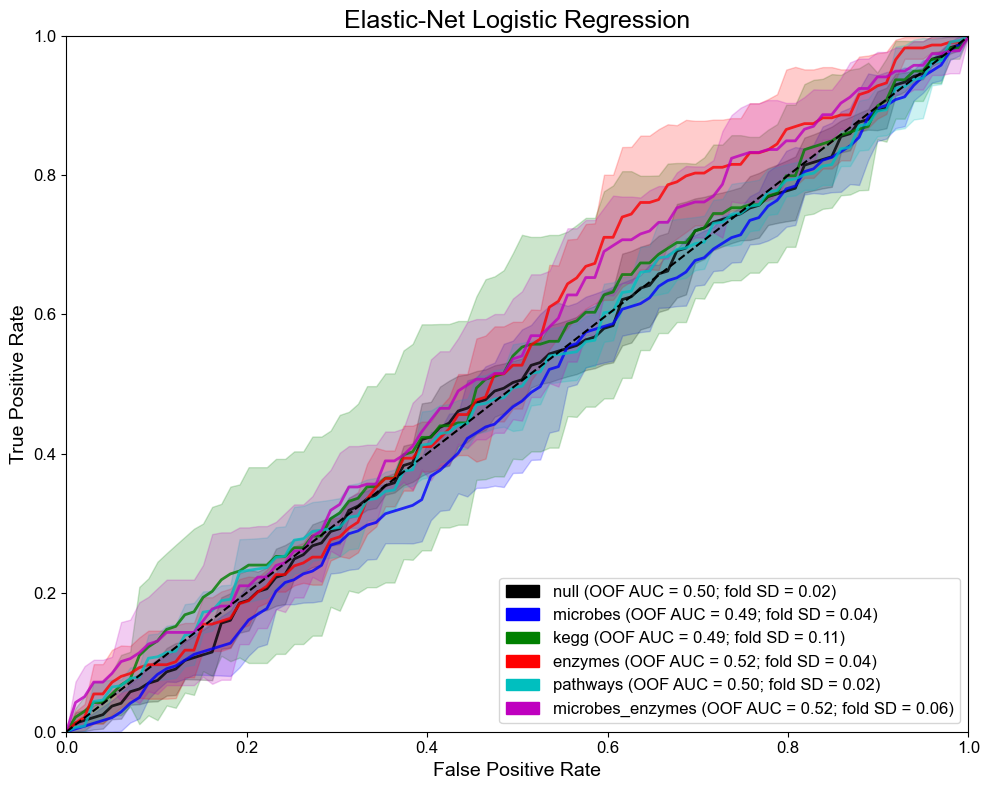


AUC summary:
            dataset  mean_fold_auc  sd_fold_auc  min_fold_auc  max_fold_auc  \
0           enzymes       0.533507     0.038685      0.496173      0.577806   
1              kegg       0.517033     0.111285      0.361395      0.654894   
2          microbes       0.474489     0.039266      0.409439      0.500000   
3  microbes_enzymes       0.538629     0.058516      0.484694      0.638298   
4              null       0.495833     0.019993      0.468112      0.522959   
5          pathways       0.501701     0.024374      0.473639      0.538265   

    oof_auc  
0  0.523489  
1  0.488995  
2  0.488400  
3  0.515376  
4  0.496394  
5  0.496819  

Best parameters by fold:
             dataset  fold         C  l1_ratio
0               null     1    0.0001      0.10
1               null     2   10.0000      0.10
2               null     3  100.0000      0.00
3               null     4    0.1000      0.50
4               null     5    0.0001      0.10
5           microbes     1

In [3]:
'''Elastic-Net Logistic Regression - Nested Cross-Validation'''

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.feature_selection import VarianceThreshold

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    roc_curve
)


# ============================================================
# CROSS-VALIDATION
# ============================================================

# Outer CV:
# unbiased model evaluation
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Inner CV:
# hyperparameter optimization
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


# ============================================================
# ELASTIC-NET HYPERPARAMETER GRID
#
# C:
#   inverse regularization strength
#
#   smaller C = stronger regularization
#
# l1_ratio:
#   0 = ridge/L2
#   1 = lasso/L1
#   intermediate = elastic net
# ============================================================

param_grid = {

    "lr__C": np.logspace(
        -4,
        2,
        7
    ),

    "lr__l1_ratio": [
        0.0,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        1.0
    ]
}


# ============================================================
# FIGURE
# ============================================================

plt.figure(
    figsize=(10, 8)
)

legend_handles = []


# ============================================================
# STORAGE
# ============================================================

fold_results = []

best_parameter_results = []

oof_results = []


# ============================================================
# LOOP OVER DATASETS
# ============================================================

for dataset, name, color in zip(
    datasets,
    dataset_names,
    colors
):

    print(
        "\n============================================"
    )

    print(
        f"Running Elastic-Net Logistic Regression: {name}"
    )

    print(
        "============================================"
    )


    # --------------------------------------------------------
    # Remove samples missing the outcome
    # --------------------------------------------------------

    dataset_model = dataset.dropna(
        subset=["sex"]
    ).copy()


    # --------------------------------------------------------
    # Predictors and outcome
    #
    # Use a Series for y rather than dataset[['sex']]
    # --------------------------------------------------------

    X = dataset_model.drop(
        columns=["sex"]
    )

    y = dataset_model["sex"]


    # --------------------------------------------------------
    # Basic QC
    # --------------------------------------------------------

    print(
        "Number of samples:",
        len(y)
    )

    print(
        "Number of predictors:",
        X.shape[1]
    )

    print(
        "\nClass distribution:"
    )

    print(
        y.value_counts()
    )


    if y.nunique() != 2:

        raise ValueError(
            f"{name}: sex must contain exactly two classes."
        )


    if y.isna().any():

        raise ValueError(
            f"{name}: outcome still contains missing values."
        )


    # --------------------------------------------------------
    # All predictors must be numeric
    # --------------------------------------------------------

    non_numeric = X.select_dtypes(
        exclude=np.number
    ).columns.tolist()


    if len(non_numeric) > 0:

        raise ValueError(
            f"{name}: non-numeric predictors detected: "
            f"{non_numeric}"
        )


    print(
        "Missing predictor values:",
        X.isna().sum().sum()
    )


    # ========================================================
    # PIPELINE
    #
    # All preprocessing occurs INSIDE CV.
    #
    # This prevents information leakage.
    # ========================================================

    pipeline = Pipeline(
        steps=[

            # -----------------------------------------------
            # Missing values
            # -----------------------------------------------

            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),


            # -----------------------------------------------
            # Remove predictors with zero variance
            # based only on training data
            # -----------------------------------------------

            (
                "variance",
                VarianceThreshold(
                    threshold=0
                )
            ),


            # -----------------------------------------------
            # Elastic net requires standardized predictors
            # -----------------------------------------------

            (
                "scale",
                StandardScaler()
            ),


            # -----------------------------------------------
            # Logistic regression
            # -----------------------------------------------

            (
                "lr",
                LogisticRegression(
                    penalty="elasticnet",
                    solver="saga",
                    max_iter=10000,
                    random_state=42
                )
            )
        ]
    )


    # ========================================================
    # OUTER-CV STORAGE
    # ========================================================

    outer_auc_scores = []

    mean_fpr = np.linspace(
        0,
        1,
        100
    )

    tprs = []


    # Every sample receives exactly one outer-CV prediction
    oof_predictions = np.full(
        len(y),
        np.nan
    )


    # ========================================================
    # OUTER CROSS-VALIDATION
    # ========================================================

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y),
        start=1
    ):

        print(
            f"\n---------- Outer fold {fold} ----------"
        )


        # ----------------------------------------------------
        # Split
        # ----------------------------------------------------

        X_train = X.iloc[
            train_idx,
            :
        ]

        X_test = X.iloc[
            test_idx,
            :
        ]

        y_train = y.iloc[
            train_idx
        ]

        y_test = y.iloc[
            test_idx
        ]


        print(
            "Train N:",
            len(y_train),
            "| Test N:",
            len(y_test)
        )


        # ====================================================
        # INNER CV HYPERPARAMETER TUNING
        # ====================================================

        cv_lr = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            verbose=0,
            refit=True
        )


        cv_lr.fit(
            X_train,
            y_train
        )


        # ----------------------------------------------------
        # Best model
        # ----------------------------------------------------

        best_model = cv_lr.best_estimator_


        print(
            f"Best inner-CV AUC: "
            f"{cv_lr.best_score_:.4f}"
        )


        print(
            "Best parameters:",
            cv_lr.best_params_
        )


        # ====================================================
        # PREDICT UNTOUCHED OUTER TEST DATA
        # ====================================================

        y_proba = best_model.predict_proba(
            X_test
        )[:, 1]


        # ----------------------------------------------------
        # Save OOF predictions
        # ----------------------------------------------------

        oof_predictions[
            test_idx
        ] = y_proba


        # ====================================================
        # OUTER-FOLD AUC
        # ====================================================

        fold_auc = roc_auc_score(
            y_test,
            y_proba
        )


        outer_auc_scores.append(
            fold_auc
        )


        print(
            f"Outer fold ROC AUC: "
            f"{fold_auc:.4f}"
        )


        # ----------------------------------------------------
        # Save fold results
        # ----------------------------------------------------

        fold_results.append(
            {
                "dataset": name,
                "fold": fold,
                "n_train": len(y_train),
                "n_test": len(y_test),
                "inner_auc": cv_lr.best_score_,
                "outer_auc": fold_auc
            }
        )


        # ----------------------------------------------------
        # Save optimal parameters
        # ----------------------------------------------------

        best_parameter_results.append(
            {
                "dataset": name,
                "fold": fold,
                "C": cv_lr.best_params_[
                    "lr__C"
                ],
                "l1_ratio": cv_lr.best_params_[
                    "lr__l1_ratio"
                ]
            }
        )


        # ====================================================
        # ROC CURVE
        # ====================================================

        fpr, tpr, _ = roc_curve(
            y_test,
            y_proba
        )


        interp_tpr = np.interp(
            mean_fpr,
            fpr,
            tpr
        )


        interp_tpr[0] = 0.0


        tprs.append(
            interp_tpr
        )


    # ========================================================
    # VERIFY OOF PREDICTIONS
    # ========================================================

    if np.isnan(
        oof_predictions
    ).any():

        raise ValueError(
            f"{name}: some samples are missing "
            "OOF predictions."
        )


    # ========================================================
    # POOLED OUT-OF-FOLD AUC
    # ========================================================

    pooled_oof_auc = roc_auc_score(
        y,
        oof_predictions
    )


    # ========================================================
    # FOLD SUMMARY
    # ========================================================

    mean_auc = np.mean(
        outer_auc_scores
    )


    sd_auc = np.std(
        outer_auc_scores,
        ddof=1
    )


    print(
        "\n============================================"
    )

    print(
        name
    )


    print(
        f"Mean fold AUC: "
        f"{mean_auc:.3f} ± {sd_auc:.3f}"
    )


    print(
        f"Pooled OOF AUC: "
        f"{pooled_oof_auc:.3f}"
    )

    print(
        "============================================"
    )


    # ========================================================
    # SAVE SAMPLE-LEVEL OOF PREDICTIONS
    # ========================================================

    for sample_id, true_y, pred_y in zip(
        X.index,
        y,
        oof_predictions
    ):

        oof_results.append(
            {
                "dataset": name,
                "sample": sample_id,
                "sex": true_y,
                "predicted_probability": pred_y
            }
        )


    # ========================================================
    # MEAN ROC
    # ========================================================

    mean_tpr = np.mean(
        tprs,
        axis=0
    )


    mean_tpr[-1] = 1.0


    std_tpr = np.std(
        tprs,
        axis=0
    )


    # --------------------------------------------------------
    # Keep SD ribbon inside valid ROC range
    # --------------------------------------------------------

    lower_tpr = np.maximum(
        mean_tpr - std_tpr,
        0
    )


    upper_tpr = np.minimum(
        mean_tpr + std_tpr,
        1
    )


    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    plt.plot(
        mean_fpr,
        mean_tpr,
        color=color,
        linewidth=2,
        alpha=0.8
    )


    plt.fill_between(
        mean_fpr,
        lower_tpr,
        upper_tpr,
        color=color,
        alpha=0.2
    )


    legend_handles.append(
        Patch(
            color=color,
            label=(
                f"{name} "
                f"(OOF AUC = {pooled_oof_auc:.2f}; "
                f"fold SD = {sd_auc:.2f})"
            )
        )
    )


# ============================================================
# RANDOM-CHANCE LINE
# ============================================================

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.5
)


# ============================================================
# FIGURE
# ============================================================

plt.xlabel(
    "False Positive Rate",
    fontsize=14
)

plt.ylabel(
    "True Positive Rate",
    fontsize=14
)

plt.title(
    "Elastic-Net Logistic Regression",
    fontsize=18
)

plt.xticks(
    fontsize=12
)

plt.yticks(
    fontsize=12
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=12
)

plt.tight_layout()

plt.show()


# ============================================================
# RESULT TABLES
# ============================================================

fold_results_df = pd.DataFrame(
    fold_results
)

best_parameters_df = pd.DataFrame(
    best_parameter_results
)

oof_results_df = pd.DataFrame(
    oof_results
)


# ============================================================
# AUC SUMMARY
# ============================================================

auc_summary = (
    fold_results_df
    .groupby("dataset")
    .agg(
        mean_fold_auc=(
            "outer_auc",
            "mean"
        ),
        sd_fold_auc=(
            "outer_auc",
            "std"
        ),
        min_fold_auc=(
            "outer_auc",
            "min"
        ),
        max_fold_auc=(
            "outer_auc",
            "max"
        )
    )
    .reset_index()
)


oof_auc_summary = (
    oof_results_df
    .groupby("dataset")
    .apply(
        lambda x: roc_auc_score(
            x["sex"],
            x["predicted_probability"]
        ),
        include_groups=False
    )
    .reset_index(
        name="oof_auc"
    )
)


auc_summary = auc_summary.merge(
    oof_auc_summary,
    on="dataset",
    how="left"
)


print(
    "\nAUC summary:"
)

print(
    auc_summary
)


print(
    "\nBest parameters by fold:"
)

print(
    best_parameters_df
)


Running Random Forest: null
Number of samples: 485
Number of predictors: 5

Class distribution:
sex
0    246
1    239
Name: count, dtype: int64
Missing predictor values: 0

---------- Outer fold 1 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.4815
Best parameters: {'rf__bootstrap': False, 'rf__criterion': 'log_loss', 'rf__max_depth': 3, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 10, 'rf__n_estimators': 865}
Outer fold ROC AUC: 0.6600

---------- Outer fold 2 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5261
Best parameters: {'rf__bootstrap': True, 'rf__criterion': 'entropy', 'rf__max_depth': 4, 'rf__max_features': 0.25, 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 5, 'rf__n_estimators': 1026}
Outer fold ROC AUC: 0.4928

---------- Outer fold 3 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5759
Best parameters: {'rf__bootstrap': False, 'rf__criterion': 'log_loss', 'rf__max_depth': 3, 'rf__max_features': 0.

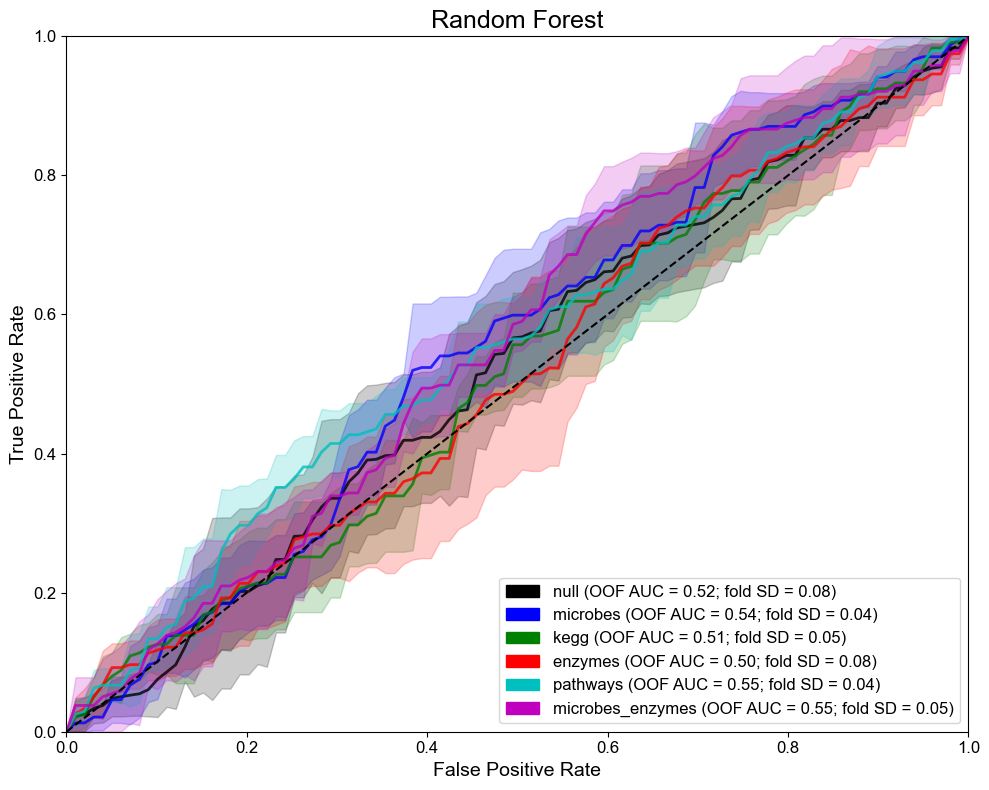


AUC summary:
            dataset  mean_fold_auc  sd_fold_auc  min_fold_auc  max_fold_auc  \
0           enzymes       0.514629     0.082465      0.427721      0.631803   
1              kegg       0.518289     0.049840      0.468112      0.587160   
2          microbes       0.552059     0.042417      0.491922      0.608511   
3  microbes_enzymes       0.558014     0.052639      0.482143      0.622553   
4              null       0.525155     0.078879      0.460459      0.660000   
5          pathways       0.556394     0.041503      0.505527      0.602041   

    oof_auc  
0  0.504966  
1  0.513182  
2  0.540412  
3  0.554087  
4  0.521864  
5  0.550549  

Best hyperparameters by fold:
             dataset  fold  inner_auc  rf__bootstrap rf__criterion  \
0               null     1   0.481546          False      log_loss   
1               null     2   0.526066           True       entropy   
2               null     3   0.575911          False      log_loss   
3               null   

In [4]:
'''Random Forest - Nested Cross-Validation'''

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch

from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.feature_selection import VarianceThreshold

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_auc_score,
    roc_curve
)

from scipy.stats import randint


# ============================================================
# CROSS-VALIDATION
# ============================================================

# Outer CV:
# unbiased evaluation of model performance
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Inner CV:
# hyperparameter optimization
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


# ============================================================
# RANDOM FOREST HYPERPARAMETER SEARCH SPACE
# ============================================================

param_distributions = {

    # Number of trees
    "rf__n_estimators": randint(
        300,
        1501
    ),

    # Maximum tree depth
    "rf__max_depth": [
        None,
        3,
        4,
        5,
        6,
        8,
        10,
        12,
        15
    ],

    # Number/fraction of predictors considered at each split
    "rf__max_features": [
        "sqrt",
        "log2",
        0.10,
        0.25,
        0.50,
        0.75
    ],

    # Minimum observations required to split a node
    "rf__min_samples_split": [
        2,
        5,
        10,
        20
    ],

    # Minimum observations in terminal leaves
    #
    # Particularly useful for preventing overfitting
    # in high-dimensional microbiome datasets.
    "rf__min_samples_leaf": [
        1,
        2,
        4,
        8,
        16
    ],

    # Split criterion
    "rf__criterion": [
        "gini",
        "entropy",
        "log_loss"
    ],

    # Bootstrap samples
    "rf__bootstrap": [
        True,
        False
    ]
}


# ============================================================
# FIGURE
# ============================================================

plt.figure(
    figsize=(10, 8)
)

legend_handles = []


# ============================================================
# STORAGE
# ============================================================

fold_results = []

best_parameter_results = []

oof_results = []


# ============================================================
# LOOP OVER DATASETS
# ============================================================

for dataset, name, color in zip(
    datasets,
    dataset_names,
    colors
):

    print(
        "\n============================================"
    )

    print(
        f"Running Random Forest: {name}"
    )

    print(
        "============================================"
    )


    # --------------------------------------------------------
    # Remove samples with missing outcome
    # --------------------------------------------------------

    dataset_model = dataset.dropna(
        subset=["sex"]
    ).copy()


    # --------------------------------------------------------
    # Define predictors and outcome
    # --------------------------------------------------------

    X = dataset_model.drop(
        columns=["sex"]
    )

    y = dataset_model["sex"]


    # --------------------------------------------------------
    # Basic QC
    # --------------------------------------------------------

    print(
        "Number of samples:",
        len(y)
    )

    print(
        "Number of predictors:",
        X.shape[1]
    )

    print(
        "\nClass distribution:"
    )

    print(
        y.value_counts()
    )


    if y.nunique() != 2:

        raise ValueError(
            f"{name}: sex must contain exactly two classes."
        )


    if y.isna().any():

        raise ValueError(
            f"{name}: outcome contains missing values."
        )


    # --------------------------------------------------------
    # Predictors should be numeric
    # --------------------------------------------------------

    non_numeric = X.select_dtypes(
        exclude=np.number
    ).columns.tolist()


    if len(non_numeric) > 0:

        raise ValueError(
            f"{name}: non-numeric predictors detected: "
            f"{non_numeric}"
        )


    print(
        "Missing predictor values:",
        X.isna().sum().sum()
    )


    # ========================================================
    # PIPELINE
    #
    # Random Forest does NOT require scaling.
    #
    # Imputation and zero-variance filtering occur inside
    # cross-validation to prevent information leakage.
    # ========================================================

    pipeline = Pipeline(
        steps=[

            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),

            (
                "variance",
                VarianceThreshold(
                    threshold=0
                )
            ),

            (
                "rf",
                RandomForestClassifier(
                    random_state=42,

                    # SearchCV handles parallelization.
                    # Avoid nested parallelism.
                    n_jobs=1
                )
            )
        ]
    )


    # ========================================================
    # OUTER-CV STORAGE
    # ========================================================

    outer_auc_scores = []

    mean_fpr = np.linspace(
        0,
        1,
        100
    )

    tprs = []


    # Each subject receives exactly one prediction from
    # a model that did not train on that subject.
    oof_predictions = np.full(
        len(y),
        np.nan
    )


    # ========================================================
    # OUTER CROSS-VALIDATION
    # ========================================================

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y),
        start=1
    ):

        print(
            f"\n---------- Outer fold {fold} ----------"
        )


        # ----------------------------------------------------
        # Split data
        # ----------------------------------------------------

        X_train = X.iloc[
            train_idx,
            :
        ]

        X_test = X.iloc[
            test_idx,
            :
        ]

        y_train = y.iloc[
            train_idx
        ]

        y_test = y.iloc[
            test_idx
        ]


        print(
            "Train N:",
            len(y_train),
            "| Test N:",
            len(y_test)
        )


        # ====================================================
        # INNER-CV HYPERPARAMETER SEARCH
        # ====================================================

        CV_rf = RandomizedSearchCV(
            estimator=pipeline,

            param_distributions=param_distributions,

            # Number of random parameter combinations
            n_iter=60,

            scoring="roc_auc",

            cv=inner_cv,

            n_jobs=-1,

            random_state=42,

            verbose=0,

            refit=True
        )


        CV_rf.fit(
            X_train,
            y_train
        )


        # ----------------------------------------------------
        # Best model from inner CV
        # ----------------------------------------------------

        best_model = CV_rf.best_estimator_


        print(
            f"Best inner-CV AUC: "
            f"{CV_rf.best_score_:.4f}"
        )


        print(
            "Best parameters:",
            CV_rf.best_params_
        )


        # ====================================================
        # OUTER TEST-SET PREDICTION
        # ====================================================

        y_proba = best_model.predict_proba(
            X_test
        )[:, 1]


        # ----------------------------------------------------
        # Save OOF predictions
        # ----------------------------------------------------

        oof_predictions[
            test_idx
        ] = y_proba


        # ====================================================
        # OUTER-FOLD ROC AUC
        # ====================================================

        fold_auc = roc_auc_score(
            y_test,
            y_proba
        )


        outer_auc_scores.append(
            fold_auc
        )


        print(
            f"Outer fold ROC AUC: "
            f"{fold_auc:.4f}"
        )


        # ----------------------------------------------------
        # Save fold-level results
        # ----------------------------------------------------

        fold_results.append(
            {
                "dataset": name,
                "fold": fold,
                "n_train": len(y_train),
                "n_test": len(y_test),
                "inner_auc": CV_rf.best_score_,
                "outer_auc": fold_auc
            }
        )


        # ----------------------------------------------------
        # Save best parameters
        # ----------------------------------------------------

        parameter_row = {
            "dataset": name,
            "fold": fold,
            "inner_auc": CV_rf.best_score_
        }


        parameter_row.update(
            CV_rf.best_params_
        )


        best_parameter_results.append(
            parameter_row
        )


        # ====================================================
        # ROC CURVE FOR THIS OUTER FOLD
        # ====================================================

        fpr, tpr, _ = roc_curve(
            y_test,
            y_proba
        )


        interp_tpr = np.interp(
            mean_fpr,
            fpr,
            tpr
        )


        interp_tpr[0] = 0.0


        tprs.append(
            interp_tpr
        )


    # ========================================================
    # VERIFY OOF PREDICTIONS
    # ========================================================

    if np.isnan(
        oof_predictions
    ).any():

        raise ValueError(
            f"{name}: some samples are missing "
            "OOF predictions."
        )


    # ========================================================
    # POOLED OUT-OF-FOLD AUC
    # ========================================================

    pooled_oof_auc = roc_auc_score(
        y,
        oof_predictions
    )


    # ========================================================
    # FOLD-LEVEL SUMMARY
    # ========================================================

    mean_auc = np.mean(
        outer_auc_scores
    )


    sd_auc = np.std(
        outer_auc_scores,
        ddof=1
    )


    print(
        "\n============================================"
    )

    print(
        name
    )

    print(
        f"Mean fold AUC: "
        f"{mean_auc:.3f} ± {sd_auc:.3f}"
    )

    print(
        f"Pooled OOF AUC: "
        f"{pooled_oof_auc:.3f}"
    )

    print(
        "============================================"
    )


    # ========================================================
    # SAVE SAMPLE-LEVEL OOF PREDICTIONS
    # ========================================================

    for sample_id, true_y, pred_y in zip(
        X.index,
        y,
        oof_predictions
    ):

        oof_results.append(
            {
                "dataset": name,
                "sample": sample_id,
                "sex": true_y,
                "predicted_probability": pred_y
            }
        )


    # ========================================================
    # MEAN ROC CURVE
    # ========================================================

    mean_tpr = np.mean(
        tprs,
        axis=0
    )


    mean_tpr[-1] = 1.0


    std_tpr = np.std(
        tprs,
        axis=0
    )


    # --------------------------------------------------------
    # Keep SD ribbon between 0 and 1
    # --------------------------------------------------------

    lower_tpr = np.maximum(
        mean_tpr - std_tpr,
        0
    )


    upper_tpr = np.minimum(
        mean_tpr + std_tpr,
        1
    )


    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    plt.plot(
        mean_fpr,
        mean_tpr,
        color=color,
        linewidth=2,
        alpha=0.8
    )


    plt.fill_between(
        mean_fpr,
        lower_tpr,
        upper_tpr,
        color=color,
        alpha=0.2
    )


    legend_handles.append(
        Patch(
            color=color,
            label=(
                f"{name} "
                f"(OOF AUC = {pooled_oof_auc:.2f}; "
                f"fold SD = {sd_auc:.2f})"
            )
        )
    )


# ============================================================
# RANDOM-CHANCE LINE
# ============================================================

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.5
)


# ============================================================
# FIGURE FORMATTING
# ============================================================

plt.xlabel(
    "False Positive Rate",
    fontsize=14
)

plt.ylabel(
    "True Positive Rate",
    fontsize=14
)

plt.title(
    "Random Forest",
    fontsize=18
)

plt.xticks(
    fontsize=12
)

plt.yticks(
    fontsize=12
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=12
)

plt.tight_layout()

plt.show()


# ============================================================
# RESULTS TABLES
# ============================================================

fold_results_df = pd.DataFrame(
    fold_results
)

best_parameters_df = pd.DataFrame(
    best_parameter_results
)

oof_results_df = pd.DataFrame(
    oof_results
)


# ============================================================
# AUC SUMMARY
# ============================================================

auc_summary = (
    fold_results_df
    .groupby("dataset")
    .agg(
        mean_fold_auc=(
            "outer_auc",
            "mean"
        ),
        sd_fold_auc=(
            "outer_auc",
            "std"
        ),
        min_fold_auc=(
            "outer_auc",
            "min"
        ),
        max_fold_auc=(
            "outer_auc",
            "max"
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# Pooled out-of-fold AUC
# ------------------------------------------------------------

oof_auc_summary = (
    oof_results_df
    .groupby("dataset")
    .apply(
        lambda x: roc_auc_score(
            x["sex"],
            x["predicted_probability"]
        ),
        include_groups=False
    )
    .reset_index(
        name="oof_auc"
    )
)


auc_summary = auc_summary.merge(
    oof_auc_summary,
    on="dataset",
    how="left"
)


print(
    "\nAUC summary:"
)

print(
    auc_summary
)


print(
    "\nBest hyperparameters by fold:"
)

print(
    best_parameters_df
)